# CSDS 340 · Case Study 1
## Exploratory Data Analysis, Model Selection, and Spam Filter Evaluation

**Course:** Introduction to Machine Learning · Fall 2026  
**Dataset:** `spamTrain1.csv` (1,500 labeled emails, 30 word-frequency features)  
**Goal:** Train a spam scorer that performs well on **ROC-AUC** and **TPR at a false positive rate (FPR) of 1%**.

This notebook is a reproducible companion to the case-study submission. It shows the *reasoning, experiments, plots, and diagnostics* behind the model—not just the final classifier.

**Notebook map:**  
1. Data loading and integrity checks  
2. Exploratory analysis: class balance, missingness, feature sparsity, informative words  
3. Experimental design and the exact grading metrics  
4. Baseline and competing algorithms  
5. Out-of-fold model evaluation and ROC/PR curves  
6. Hyperparameter sensitivity and missing-value ablations  
7. Repeatability across multiple CV shuffles  
8. Threshold calibration, error analysis, and permutation importance  
9. Final `predictTest()` implementation and grader compatibility

**Reproducibility:** All data-dependent fitting takes place *inside* training folds. The held-out test set from the instructor is not used and is not supplied with this notebook.

### Running the notebook

Place `spamTrain1.csv` beside the notebook (or keep both in the shared `/mnt/data` workspace). Run cells from top to bottom. Required packages: `numpy`, `pandas`, `matplotlib`, `scikit-learn`, `IPython`, and `jupyter`/`notebook`. No GPU is needed. Some model-comparison and permutation-importance cells may take longer than plots.

The provided `evaluateClassifier.py` references a *separate* `spamTrain2.csv` that is not currently supplied; therefore this notebook uses **stratified cross-validation**, not that missing file or the professor's hidden test set.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier, VotingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, precision_recall_curve,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.svm import SVC

SEED = 340
FPR_TARGET = 0.01
np.random.seed(SEED)
plt.rcParams.update({'figure.figsize': (8, 4.5), 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
pd.set_option('display.max_columns', 35)
print('Python:', sys.version.split()[0], '| scikit-learn version:')
import sklearn
print(sklearn.__version__)

Python: 3.13.5 | scikit-learn version:
1.8.0


## 1. Read and validate the data

In [2]:
# If running from a different folder, edit DATA_PATH to your full file path.
candidates = [Path('spamTrain1.csv'), Path('../spamTrain1.csv'),
              Path('/mnt/data/spamTrain1.csv')]
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Place spamTrain1.csv beside the notebook, or edit DATA_PATH.')

raw = np.loadtxt(DATA_PATH, delimiter=',')
assert raw.ndim == 2 and raw.shape[1] == 31, f'Expected 30 features + label: {raw.shape}'
X = raw[:, :30].astype(float)
y = raw[:, 30].astype(int)
feature_names = [f'Feature {i:02d}' for i in range(1, 31)]
missing_mask = X == -1
X_nan = np.where(missing_mask, np.nan, X)  # FOR DESCRIPTIVE ANALYSIS ONLY

assert set(np.unique(y)).issubset({0, 1}), 'Unexpected target labels.'
assert np.all((X == -1) | ((0 <= X) & (X <= 1))), 'Feature outside valid range.'
assert np.isfinite(raw).all(), 'Unexpected NaN or infinity in file.'
assert np.unique(X, axis=0).shape[0] == len(X), 'Duplicate feature rows detected; investigate CV leakage.'

print('File:', DATA_PATH.resolve())
print('Shape:', raw.shape, '| X:', X.shape, '| y:', y.shape)
print('Labels: 0=ham, 1=spam')
display(pd.DataFrame(raw[:6], columns=feature_names + ['Label']).round(4))

File: /mnt/data/spamTrain1.csv
Shape: (1500, 31) | X: (1500, 30) | y: (1500,)
Labels: 0=ham, 1=spam


,Feature 01,Feature 02,Feature 03,Feature 04,Feature 05,Feature 06,Feature 07,Feature 08,Feature 09,Feature 10,Feature 11,Feature 12,Feature 13,Feature 14,Feature 15,Feature 16,Feature 17,Feature 18,Feature 19,Feature 20,Feature 21,Feature 22,Feature 23,Feature 24,Feature 25,Feature 26,Feature 27,Feature 28,Feature 29,Feature 30,Label
0,0.00,0.0000,0.0,0.0014,0.0,0.0,0.0000,0.0000,0.0,0.0000,0.0,0.0,0.0188,-1.0,0.0014,0.0000,0.0,-1.0000,0.0,0.0029,0.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000,0.0029,1.0
1,0.00,0.0000,0.0,0.0031,-1.0,0.0,0.0000,-1.0000,0.0,0.0000,0.0,0.0,0.0000,0.0,0.0000,0.0058,0.0,0.0000,0.0,-1.0000,-1.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0031,0.0094,1.0
2,0.00,-1.0000,0.0,0.0045,-1.0,0.0,0.0000,0.0159,0.0,0.0022,0.0,0.0,0.0340,-1.0,0.0000,0.0000,-1.0,0.0000,-1.0,0.0000,0.0,-1.0,0.0,0.0088,0.0,0.0,0.0,-1.0,0.0102,0.0011,1.0
3,0.00,0.0050,0.0,-1.0000,0.0,0.0,-1.0000,0.0000,0.0,0.0000,0.0,0.0,0.0030,0.0,0.0000,-1.0000,0.0,0.0035,0.0,0.0000,0.0,0.0,0.0,-1.0000,0.0,0.0,0.0,0.0,0.0000,0.0133,1.0
4,0.01,0.0000,0.0,0.0000,0.0,-1.0,0.0125,0.0000,0.0,0.0000,0.0,0.0,0.0137,0.0,-1.0000,-1.0000,0.0,0.0000,0.0,0.0000,0.0,0.0,0.0,0.0093,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0
5,0.00,0.0065,0.0,-1.0000,0.0,0.0,0.0212,0.0000,0.0,-1.0000,0.0,0.0,0.0443,-1.0,0.0000,0.0000,-1.0,0.0029,-1.0,0.0000,-1.0,0.0,0.0,0.0003,0.0,-1.0,0.0,0.0,-1.0000,0.0000,0.0


In [3]:
summary = pd.DataFrame({
    'Statistic': ['Emails', 'Features per email', 'Ham emails', 'Spam emails',
                  'Spam prevalence', 'Missing cells (-1)', 'Missing rate',
                  'Zeros among observed cells', 'Total duplicate feature rows'],
    'Value': [len(y), X.shape[1], int(np.sum(y==0)), int(np.sum(y==1)),
              f'{np.mean(y):.1%}', int(missing_mask.sum()),
              f'{missing_mask.mean():.2%}',
              f'{np.mean(X[~missing_mask] == 0):.2%}',
              int(len(X) - len(np.unique(X, axis=0)))]
})
display(summary)

,Statistic,Value
0,Emails,1500
1,Features per email,30
2,Ham emails,879
3,Spam emails,621
4,Spam prevalence,41.4%
5,Missing cells (-1),8997
6,Missing rate,19.99%
7,Zeros among observed cells,81.90%
8,Total duplicate feature rows,0


## 2. Exploratory data analysis

### 2.1 Class balance

**Why it matters:** The labels are not exactly balanced. Plain classification accuracy and any threshold picked solely to maximize accuracy can hide false positives, which are particularly costly for an email filter.

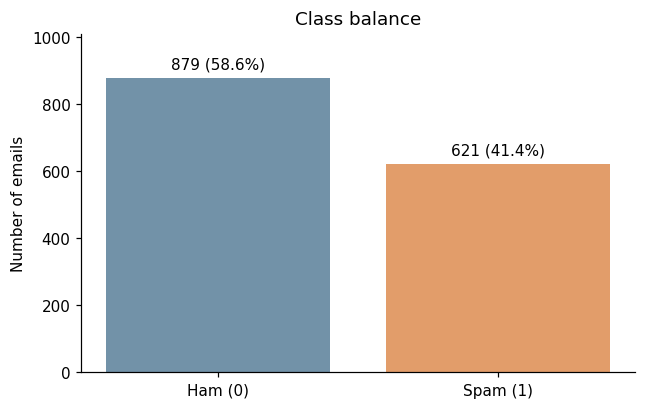

In [4]:
counts = pd.Series(y).map({0:'Ham (0)',1:'Spam (1)'}).value_counts().reindex(['Ham (0)', 'Spam (1)'])
fig, ax = plt.subplots(figsize=(6.5, 4))
bars = ax.bar(counts.index, counts.values, color=['#7292A8', '#E29D6A'])
ax.bar_label(bars, labels=[f'{v:,} ({v/len(y):.1%})' for v in counts.values], padding=4)
ax.set(ylabel='Number of emails', title='Class balance')
ax.set_ylim(0, counts.max()*1.15)
plt.show()

### 2.2 Missing values (encoded as `-1`)

The assignment states that `-1` means *missing*, not a negative frequency. It must not be treated as an ordinary word proportion. Missingness might be related to the target (useful indicator) or entirely uninformative (possible noise). We inspect both possibilities without fitting any model.

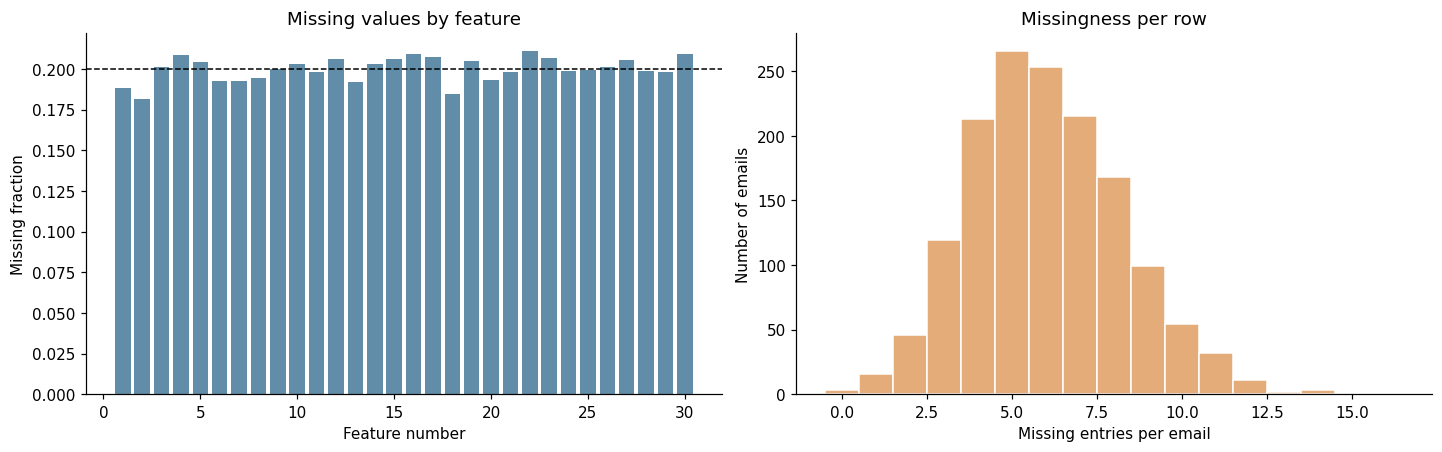

Missing fraction by class:
  Ham:  19.989%
  Spam: 20.000%


,Feature,Ham missing rate,Spam missing rate,Spam minus ham
1,Feature 02,0.165,0.205,0.040
10,Feature 11,0.182,0.221,0.039
25,Feature 26,0.217,0.179,-0.039
15,Feature 16,0.195,0.230,0.036
9,Feature 10,0.190,0.222,0.032
3,Feature 04,0.197,0.225,0.029
18,Feature 19,0.193,0.221,0.027
26,Feature 27,0.215,0.192,-0.023
4,Feature 05,0.195,0.217,0.023
21,Feature 22,0.221,0.198,-0.023


In [5]:
missing_by_feature = missing_mask.mean(axis=0)
missing_by_class = pd.DataFrame({
    'Feature': feature_names,
    'Ham missing rate': missing_mask[y==0].mean(axis=0),
    'Spam missing rate': missing_mask[y==1].mean(axis=0),
})
missing_by_class['Spam minus ham'] = (missing_by_class['Spam missing rate']
                                       - missing_by_class['Ham missing rate'])

fig, axs = plt.subplots(1, 2, figsize=(13,4), constrained_layout=True)
axs[0].bar(range(1,31), missing_by_feature, color='#628DA8')
axs[0].axhline(missing_mask.mean(), ls='--', color='black', lw=1)
axs[0].set(xlabel='Feature number', ylabel='Missing fraction', title='Missing values by feature')
axs[1].hist(missing_mask.sum(axis=1), bins=np.arange(-0.5, 17.5), color='#E4AC78', edgecolor='white')
axs[1].set(xlabel='Missing entries per email', ylabel='Number of emails', title='Missingness per row')
plt.show()

print('Missing fraction by class:')
print(f'  Ham:  {missing_mask[y==0].mean():.3%}')
print(f'  Spam: {missing_mask[y==1].mean():.3%}')
display(missing_by_class.reindex(missing_by_class['Spam minus ham'].abs().sort_values(ascending=False).index).head(10).round(3))

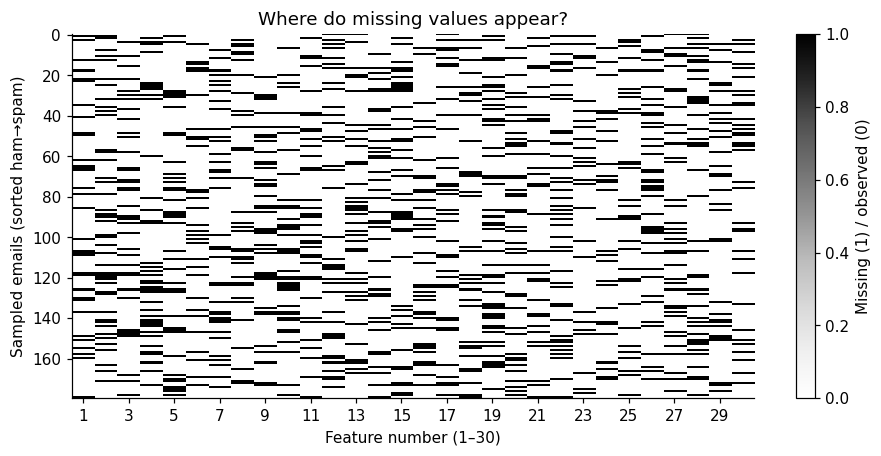

In [6]:
# Dark pixels correspond to missing feature values. Sample rows for legibility.
sampled_idx = np.random.default_rng(SEED).choice(len(y), size=min(180,len(y)), replace=False)
order = sampled_idx[np.argsort(y[sampled_idx])]
fig, ax = plt.subplots(figsize=(10,4.3))
im = ax.imshow(missing_mask[order], interpolation='nearest', aspect='auto', cmap='Greys', vmin=0, vmax=1)
ax.set(xlabel='Feature number (1–30)', ylabel='Sampled emails (sorted ham→spam)',
       title='Where do missing values appear?')
ax.set_xticks(np.arange(0,30,2), np.arange(1,31,2))
fig.colorbar(im, ax=ax, label='Missing (1) / observed (0)')
plt.show()

### 2.3 Zero inflation and word-frequency distributions

Most observed word proportions may be zero because an email contains only some of the tracked terms. We compare (i) a word being **present** (`value > 0`), and (ii) its average observed proportion, separately for spam and ham.

In [7]:
feature_stats = pd.DataFrame({
    'Feature': feature_names,
    'Missing %': 100*missing_by_feature,
    'Zero % of observed': 100*np.nanmean(X_nan == 0, axis=0) /
                          (1 - missing_by_feature),
    'Observed mean': np.nanmean(X_nan, axis=0),
    'Observed std': np.nanstd(X_nan, axis=0),
    'Observed max': np.nanmax(X_nan, axis=0),
})
# For presence-by-class, denominator excludes values that were not observed.
presence_ham = np.sum((X[y==0] > 0), axis=0) / np.sum(X[y==0] != -1, axis=0)
presence_spam = np.sum((X[y==1] > 0), axis=0) / np.sum(X[y==1] != -1, axis=0)
feature_stats['Presence | ham'] = presence_ham
feature_stats['Presence | spam'] = presence_spam
feature_stats['Difference (spam - ham)'] = presence_spam-presence_ham

display(feature_stats.sort_values('Difference (spam - ham)', key=np.abs, ascending=False).head(12).round(4))

,Feature,Missing %,Zero % of observed,Observed mean,Observed std,Observed max,Presence | ham,Presence | spam,Difference (spam - ham)
19,Feature 20,19.3333,70.2479,0.0028,0.0091,0.2000,0.0912,0.5827,0.4915
3,Feature 04,20.8667,62.5105,0.0031,0.0065,0.0625,0.1983,0.6341,0.4358
8,Feature 09,20.0000,81.4167,0.0012,0.0040,0.0540,0.0201,0.4139,0.3937
29,Feature 30,20.9333,55.8179,0.0032,0.0056,0.0434,0.2909,0.6525,0.3616
7,Feature 08,19.4667,72.2682,0.0023,0.0059,0.0755,0.1506,0.4544,0.3038
4,Feature 05,20.4000,78.3920,0.0016,0.0050,0.0714,0.0975,0.3889,0.2914
9,Feature 10,20.3333,80.3347,0.0022,0.0134,0.1428,0.0913,0.3520,0.2607
28,Feature 29,19.8000,83.5411,0.0009,0.0031,0.0526,0.0644,0.3036,0.2392
6,Feature 07,19.2667,82.1635,0.0012,0.0036,0.0454,0.2667,0.0553,-0.2113
10,Feature 11,19.8000,89.9418,0.0009,0.0049,0.0625,0.0195,0.2211,0.2016


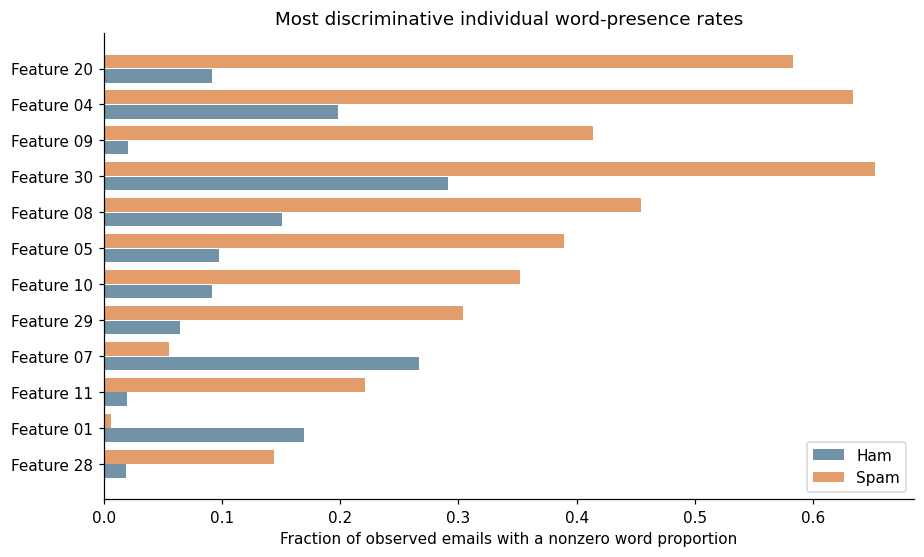

In [8]:
ranked = feature_stats.reindex(feature_stats['Difference (spam - ham)'].abs().sort_values(ascending=False).index)
top_features = ranked.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9.5,5.5))
pos = np.arange(len(top_features))
ax.barh(pos-0.20, top_features['Presence | ham'], height=.38, label='Ham', color='#7292A8')
ax.barh(pos+0.20, top_features['Presence | spam'], height=.38, label='Spam', color='#E29D6A')
ax.set_yticks(pos, top_features['Feature'])
ax.set(xlabel='Fraction of observed emails with a nonzero word proportion',
       title='Most discriminative individual word-presence rates')
ax.legend()
plt.show()

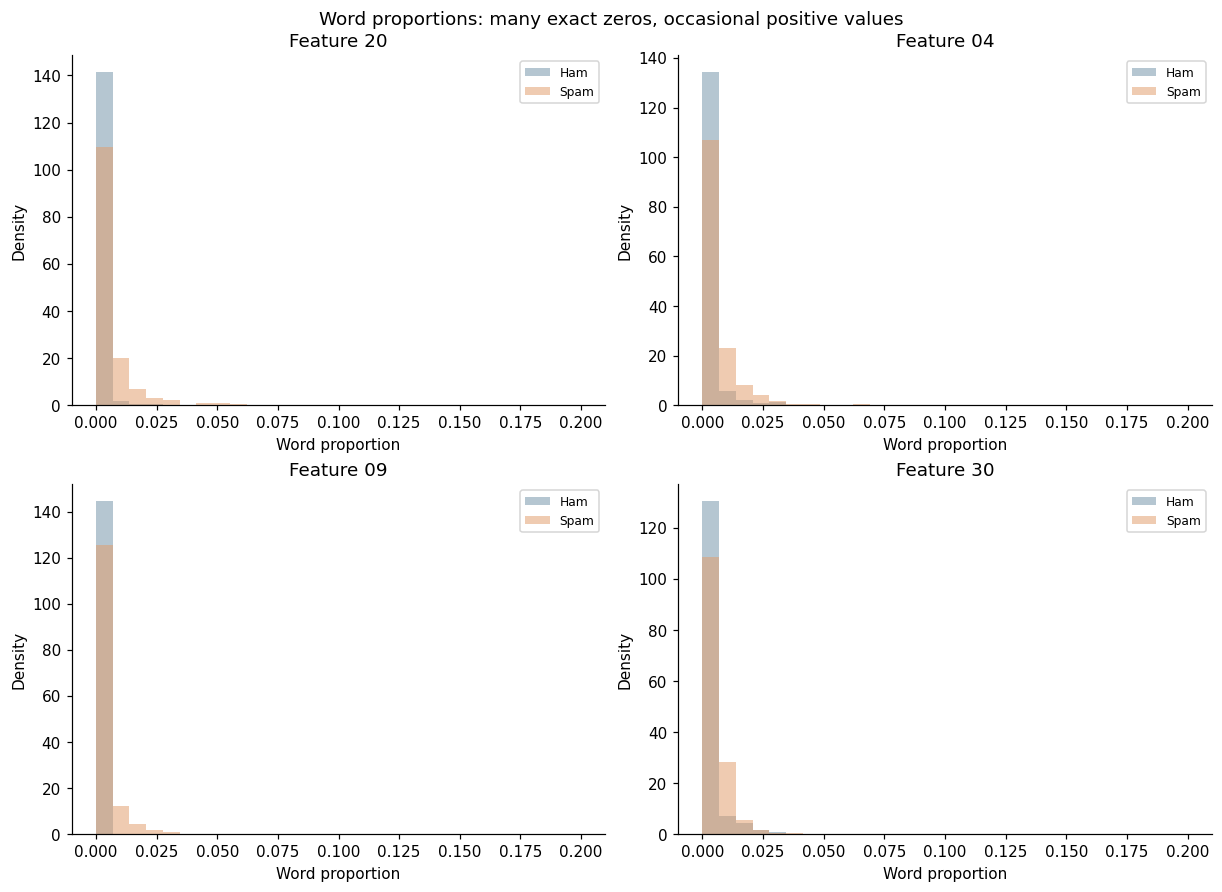

In [9]:
# Show actual proportion distributions for the four largest differences.
selected = ranked['Feature'].iloc[:4].tolist()
fig, axs = plt.subplots(2,2,figsize=(11,7.8),constrained_layout=True)
for ax, feat in zip(axs.flat, selected):
    j=feature_names.index(feat)
    for label, name, color in [(0,'Ham','#7292A8'),(1,'Spam','#E29D6A')]:
        values=X_nan[y==label,j]
        values=values[np.isfinite(values)]
        ax.hist(values, bins=np.linspace(0,.2,30), alpha=.52, density=True,
                label=name, color=color)
    ax.set(title=feat, xlabel='Word proportion', ylabel='Density')
    ax.legend(fontsize=8)
plt.suptitle('Word proportions: many exact zeros, occasional positive values', y=1.02)
plt.show()

### 2.4 Feature relationships

Correlated word-frequency features violate naïve Bayes's conditional-independence assumption and may make linear decision rules inadequate. The following correlation plot is **only a diagnostic**: pairwise correlations ignore missing entries, and no information from this plot is passed into a fitted preprocessing pipeline.

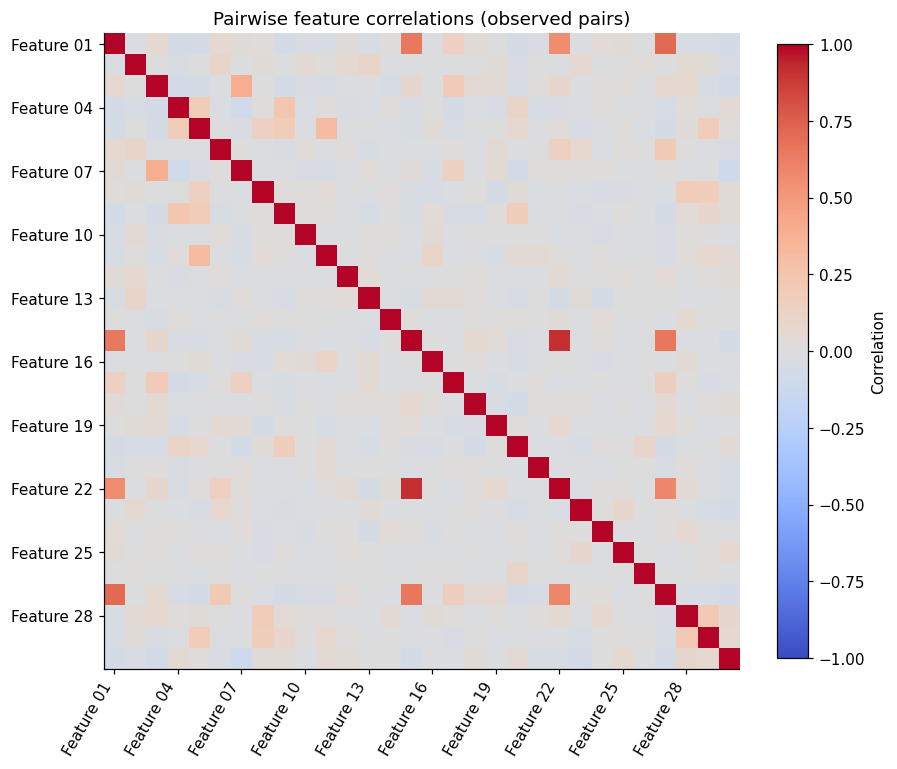

,Feature A,Feature B,Correlation
321,Feature 15,Feature 22,0.907
25,Feature 01,Feature 27,0.705
326,Feature 15,Feature 27,0.651
13,Feature 01,Feature 15,0.644
403,Feature 22,Feature 27,0.584
20,Feature 01,Feature 22,0.558
60,Feature 03,Feature 07,0.393
115,Feature 05,Feature 11,0.300
88,Feature 04,Feature 09,0.228
432,Feature 28,Feature 29,0.205


In [10]:
feature_df = pd.DataFrame(X_nan, columns=feature_names)
corr = feature_df.corr()
fig, ax = plt.subplots(figsize=(9,7.5))
im=ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(np.arange(0,30,3), feature_names[::3], rotation=60, ha='right')
ax.set_yticks(np.arange(0,30,3), feature_names[::3])
ax.set_title('Pairwise feature correlations (observed pairs)')
fig.colorbar(im, ax=ax, fraction=.04, label='Correlation')
plt.show()

pairs=[]
for i in range(30):
    for j in range(i+1,30):
        pairs.append((feature_names[i],feature_names[j],float(corr.iloc[i,j])))
pair_df=pd.DataFrame(pairs, columns=['Feature A','Feature B','Correlation'])
display(pair_df.sort_values('Correlation', key=lambda s: s.abs(), ascending=False).head(10).round(3))

## 3. Evaluation protocol and grading metrics

**ROC-AUC** evaluates how well spam messages rank above ham across all thresholds. **TPR at 1% FPR** focuses on catching spam while incorrectly flagging very few legitimate emails.

\[
\mathrm{TPR}=\frac{TP}{TP+FN},\qquad
\mathrm{FPR}=\frac{FP}{FP+TN}.
\]

The provided `evaluateClassifier.py` calls `roc_curve` and linearly interpolates at `FPR = 0.01`. The helper below computes the same operating-point quantity from held-out score/label pairs. This *evaluation* step uses held-out labels, which is appropriate; preprocessing, model training, and threshold selection must not use those labels.

**CV strategy:** Stratified 5-fold CV with shuffle (`random_state=340`). Every email receives one out-of-fold (OOF) prediction. The AUC and TPR@1% are computed from all OOF scores. Fold-specific metrics are also shown, but at 1% FPR a single held-out fold contains fewer than ~200 ham messages, making this statistic noisy.

In [11]:
def tpr_at_fpr(y_true, scores, desired_fpr=FPR_TARGET):
    fpr, tpr, _ = roc_curve(y_true, scores)
    # roc_curve fpr is nondecreasing; interpolation matches the grader's idea.
    return float(np.interp(desired_fpr, fpr, tpr))

def ranking_metrics(y_true, scores):
    return {
        'ROC-AUC': float(roc_auc_score(y_true, scores)),
        'TPR@1%FPR': tpr_at_fpr(y_true, scores),
        'Average precision': float(average_precision_score(y_true, scores)),
    }

def scores_for_spam(model, test_features):
    if hasattr(model, 'predict_proba'):
        return np.asarray(model.predict_proba(test_features)[:,1], dtype=float)
    return np.asarray(model.decision_function(test_features), dtype=float)

def evaluate_oof(estimator, X_data, y_data, seed=SEED, n_splits=5):
    """Each score comes from a model that never fit on that email."""
    folds = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    oof = np.full(len(y_data), np.nan)
    fold_rows = []
    for fold, (i_train, i_val) in enumerate(folds.split(X_data,y_data), start=1):
        model = clone(estimator)
        model.fit(X_data[i_train], y_data[i_train])
        fold_scores = scores_for_spam(model, X_data[i_val])
        oof[i_val] = fold_scores
        fold_rows.append({'Fold':fold, **ranking_metrics(y_data[i_val],fold_scores)})
    assert np.isfinite(oof).all()
    return oof, pd.DataFrame(fold_rows)

# Quick metric sanity checks: perfect ranking -> 1.0, inverted ranking -> 0.0.
assert np.isclose(roc_auc_score([0,0,1,1],[.1,.2,.8,.9]),1.0)
assert np.isclose(roc_auc_score([0,0,1,1],[.8,.9,.1,.2]),0.0)
print('Metric helpers validated.')

Metric helpers validated.


## 4. Set up the baseline and competing algorithms

Missing-value replacement and scaling are always part of a scikit-learn **pipeline**, so their parameters are learned on the training fold only. The tree models can learn nonlinear feature interactions without scaling. Native histogram gradient boosting routes `NaN` down learned branches; the random forest uses median imputation plus explicit missing-value indicators.

Candidate models:

| Model | Preprocessing | Why include it? |
|---|---|---|
| Gaussian NB (instructor baseline) | Mean imputation | Assignment's required reference |
| Logistic regression | Mean imputation + standardization | Regularized linear comparison |
| Logistic regression + missing indicators | Mean + indicators + scaling | Tests whether missingness helps a linear model |
| RBF SVM | Mean imputation + standardization | Flexible nonlinear boundary |
| Random forest | Median + missing indicators | Nonlinear interactions and robust averaging |
| Histogram gradient boosting | Convert -1 to `NaN` | Native missing routing and efficient boosting |
| **60/40 voting ensemble** | Each member has its own preprocessing | Reproduces the submitted final model |

In [12]:
def sentinel_to_nan(z):
    arr = np.asarray(z, dtype=float)
    return np.where(arr == -1, np.nan, arr)

def make_hgb(n_iter=350, leaf_nodes=4, min_leaf=20, regularization=1.0):
    return make_pipeline(
        FunctionTransformer(sentinel_to_nan, validate=False),
        HistGradientBoostingClassifier(
            max_iter=n_iter, learning_rate=.05, max_leaf_nodes=leaf_nodes,
            min_samples_leaf=min_leaf, l2_regularization=regularization,
            random_state=SEED,
        )
    )

def make_forest(add_indicator=True, trees=300, leaf=3):
    return make_pipeline(
        SimpleImputer(missing_values=-1, strategy='median', add_indicator=add_indicator),
        RandomForestClassifier(n_estimators=trees, min_samples_leaf=leaf,
                               max_features='sqrt', n_jobs=1, random_state=SEED)
    )

def make_final_ensemble(boost_weight=.60):
    return VotingClassifier(
        estimators=[('boost',make_hgb()), ('forest',make_forest())],
        voting='soft', weights=[boost_weight,1-boost_weight]
    )

models={
    'Gaussian NB baseline': make_pipeline(
        SimpleImputer(missing_values=-1,strategy='mean'), GaussianNB()),
    'Logistic regression': make_pipeline(
        SimpleImputer(missing_values=-1,strategy='mean'),
        StandardScaler(), LogisticRegression(C=1,max_iter=3000,random_state=SEED)),
    'Logistic + missing flags': make_pipeline(
        SimpleImputer(missing_values=-1,strategy='mean',add_indicator=True),
        StandardScaler(),LogisticRegression(C=1,max_iter=3000,random_state=SEED)),
    'RBF SVM': make_pipeline(
        SimpleImputer(missing_values=-1,strategy='mean'), StandardScaler(),
        SVC(C=1,kernel='rbf',gamma='scale')),
    'Random forest': make_forest(),
    'Histogram gradient boosting': make_hgb(),
    'Final: 60% HGB + 40% RF': make_final_ensemble(),
}
print('Comparison models:',len(models))

Comparison models: 7


## 5. Model comparison with out-of-fold predictions

All methods use exactly the same CV split and the same feature/label data. The ensemble combines **predicted probabilities**, not hard class labels. The RBF SVM uses its `decision_function` values, which are suitable for ranking (AUC/TPR@FPR) even though they are not probabilities.

In [13]:
comparison_rows=[]
oof_by_model={}
fold_results={}
for name, estimator in models.items():
    scores, folds = evaluate_oof(estimator,X,y,seed=SEED)
    oof_by_model[name] = scores
    fold_results[name] = folds
    comparison_rows.append({'Algorithm':name, **ranking_metrics(y,scores),
                            'Mean fold AUC':folds['ROC-AUC'].mean()})
comparison=pd.DataFrame(comparison_rows).sort_values(['TPR@1%FPR','ROC-AUC'],ascending=False)
display(comparison.style.format({c:'{:.3f}' for c in comparison.columns if c!='Algorithm'}))

,Algorithm,ROC-AUC,TPR@1%FPR,Average precision,Mean fold AUC
6,Final: 60% HGB + 40% RF,0.919,0.541,0.912,0.919
5,Histogram gradient boosting,0.920,0.527,0.915,0.920
4,Random forest,0.910,0.519,0.902,0.909
3,RBF SVM,0.896,0.404,0.876,0.896
1,Logistic regression,0.895,0.333,0.857,0.895
2,Logistic + missing flags,0.888,0.324,0.851,0.888
0,Gaussian NB baseline,0.817,0.121,0.771,0.824


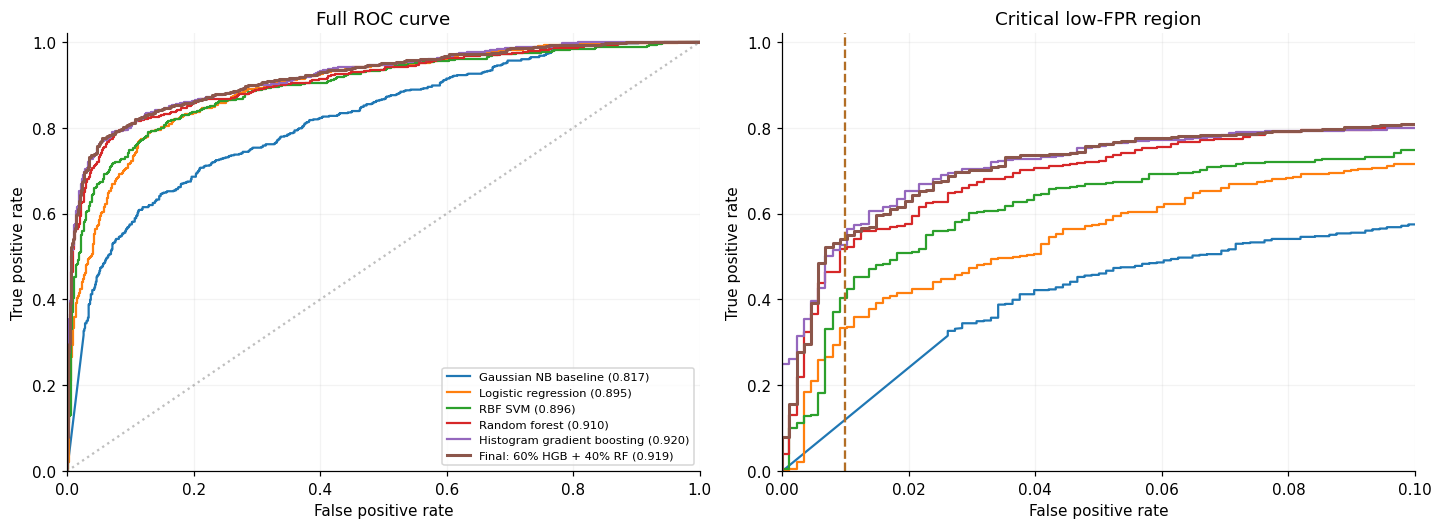

In [14]:
# The most relevant comparison includes both the full ROC and its first 10% FPR.
plot_order=['Gaussian NB baseline', 'Logistic regression', 'RBF SVM',
            'Random forest', 'Histogram gradient boosting', 'Final: 60% HGB + 40% RF']
fig, axarr = plt.subplots(1, 2, figsize=(13,4.7), constrained_layout=True)
for name in plot_order:
    fpr,tpr,_=roc_curve(y,oof_by_model[name])
    auc=roc_auc_score(y,oof_by_model[name])
    for ax in axarr:
        ax.plot(fpr,tpr, lw=2 if name.startswith('Final:') else 1.45,
                label=f'{name} ({auc:.3f})')
axarr[0].plot([0,1],[0,1],ls=':',color='gray',alpha=.5)
axarr[0].set(title='Full ROC curve',xlabel='False positive rate',ylabel='True positive rate',xlim=(0,1),ylim=(0,1.02))
axarr[1].axvline(FPR_TARGET,ls='--',color='#b26e25',label='1% FPR target')
axarr[1].set(title='Critical low-FPR region',xlabel='False positive rate',ylabel='True positive rate',xlim=(0,.10),ylim=(0,1.02))
for ax in axarr: ax.grid(alpha=.15)
axarr[0].legend(loc='lower right',fontsize=7.5)
plt.show()

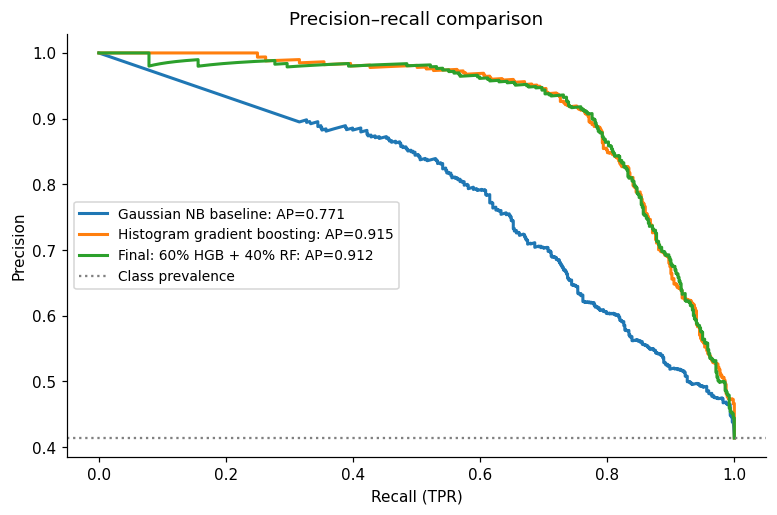

In [15]:
fig,ax=plt.subplots(figsize=(8.2,5))
for name in ['Gaussian NB baseline','Histogram gradient boosting','Final: 60% HGB + 40% RF']:
    precision,recall,_=precision_recall_curve(y,oof_by_model[name])
    ax.plot(recall,precision,lw=2,label=f'{name}: AP={average_precision_score(y,oof_by_model[name]):.3f}')
ax.axhline(y.mean(),ls=':',color='gray',label='Class prevalence')
ax.set(xlabel='Recall (TPR)',ylabel='Precision',title='Precision–recall comparison')
ax.legend(fontsize=9)
plt.show()

### How to interpret these results

The **overall ROC-AUC** measures ranking across all thresholds, whereas **TPR@1%FPR** counts how much spam is caught in a very conservative region. There can be a tradeoff: a model with slightly higher total AUC can be worse at 1% FPR. These are *CV estimates*; they do not establish performance on the separate instructor test set.

## 6. Sensitivity checks and preprocessing ablations

The full case-study workflow should explain **why** the final model was selected. We vary a small number of meaningful parameters and missing-data choices rather than blindly search huge grids. All alternatives are evaluated without leaking information from validation folds into training.

**Caution:** Since we compare settings on the same 1,500 labeled emails, the winning setting may be somewhat optimistic due to model selection. Confirm choices with the second labeled batch or nested CV when available.

In [16]:
# Controlled HGB complexity comparison; n_iter controls boosting rounds, leaf_nodes complexity.
hgb_variations={
    'HGB: 150 rounds, 4 leaves':make_hgb(n_iter=150,leaf_nodes=4),
    'HGB: 350 rounds, 2 leaves':make_hgb(n_iter=350,leaf_nodes=2),
    'HGB: 350 rounds, 4 leaves (chosen)':make_hgb(n_iter=350,leaf_nodes=4),
    'HGB: 350 rounds, 8 leaves':make_hgb(n_iter=350,leaf_nodes=8),
}
res=[]
for name, estimator in hgb_variations.items():
    s,_=evaluate_oof(estimator,X,y)
    res.append({'Setting':name,**ranking_metrics(y,s)})
hgb_tuning=pd.DataFrame(res)
display(hgb_tuning.style.format({c:'{:.3f}' for c in hgb_tuning.columns if c!='Setting'}))

,Setting,ROC-AUC,TPR@1%FPR,Average precision
0,"HGB: 150 rounds, 4 leaves",0.918,0.475,0.910
1,"HGB: 350 rounds, 2 leaves",0.919,0.535,0.909
2,"HGB: 350 rounds, 4 leaves (chosen)",0.920,0.527,0.915
3,"HGB: 350 rounds, 8 leaves",0.917,0.520,0.912


In [17]:
# The key comparison: native NaN handling vs treating -1 numerically vs imputation.
# Including -1 as an ordinary value is intentionally tested as a *bad assumption*.
missing_treatments={
    'HGB: native NaN routing':make_hgb(),
    'HGB: -1 as numeric (ablation)':HistGradientBoostingClassifier(
        max_iter=350,learning_rate=.05,max_leaf_nodes=4,
        min_samples_leaf=20,l2_regularization=1,random_state=SEED),
    'HGB: median imputation':make_pipeline(
        SimpleImputer(missing_values=-1,strategy='median'),
        HistGradientBoostingClassifier(max_iter=350,learning_rate=.05,
            max_leaf_nodes=4,min_samples_leaf=20,l2_regularization=1,random_state=SEED)),
    'RF: median, no flags':make_forest(add_indicator=False),
    'RF: median + flags':make_forest(add_indicator=True),
}
ablations=[]
for name,model in missing_treatments.items():
    s,_=evaluate_oof(model,X,y)
    ablations.append({'Preprocessing':name,**ranking_metrics(y,s)})
ablations=pd.DataFrame(ablations)
display(ablations.style.format({c:'{:.3f}' for c in ablations.columns if c!='Preprocessing'}))

,Preprocessing,ROC-AUC,TPR@1%FPR,Average precision
0,HGB: native NaN routing,0.920,0.527,0.915
1,HGB: -1 as numeric (ablation),0.920,0.506,0.912
2,HGB: median imputation,0.920,0.506,0.910
3,"RF: median, no flags",0.911,0.433,0.898
4,RF: median + flags,0.910,0.519,0.902


,Weight on HGB,ROC-AUC,TPR@1%FPR,Average precision
0,0%,0.910,0.519,0.902
1,20%,0.914,0.531,0.906
2,40%,0.917,0.533,0.909
3,60%,0.919,0.541,0.912
4,80%,0.920,0.535,0.914
5,100%,0.920,0.527,0.915


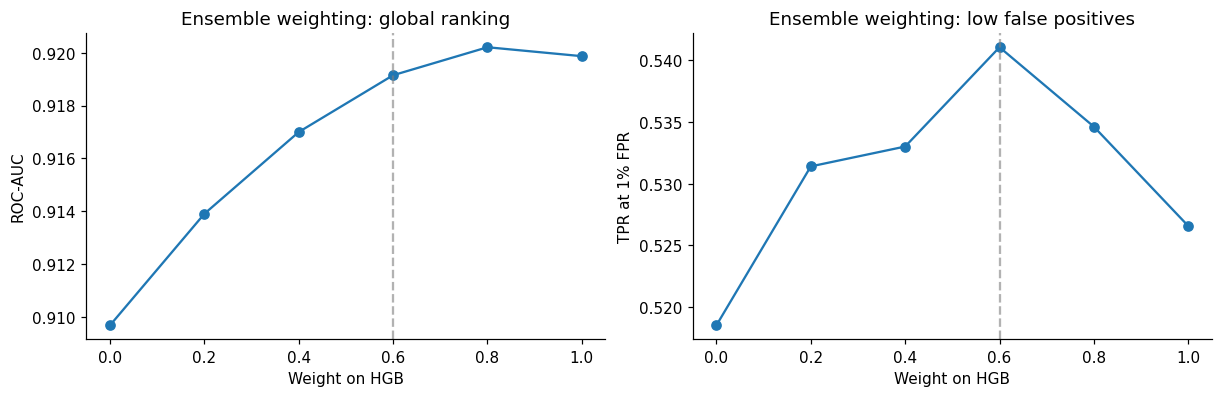

In [18]:
# Check ensemble weight sensitivity without training on the instructor's hidden test data.
weights=[0.0,.2,.4,.6,.8,1.0]
w_rows=[]
# Both models' OOF probabilities were produced on identical CV folds.
boost_oof=oof_by_model['Histogram gradient boosting']
forest_oof=oof_by_model['Random forest']
for w in weights:
    blended=w*boost_oof+(1-w)*forest_oof
    w_rows.append({'Weight on HGB':w, **ranking_metrics(y,blended)})
weight_results=pd.DataFrame(w_rows)
display(weight_results.style.format({'Weight on HGB':'{:.0%}','ROC-AUC':'{:.3f}',
                                     'TPR@1%FPR':'{:.3f}','Average precision':'{:.3f}'}))

fig, axs=plt.subplots(1,2,figsize=(11,3.5),constrained_layout=True)
axs[0].plot(weight_results['Weight on HGB'],weight_results['ROC-AUC'],marker='o')
axs[1].plot(weight_results['Weight on HGB'],weight_results['TPR@1%FPR'],marker='o')
for ax in axs: ax.axvline(.6,color='gray',ls='--',alpha=.6);ax.set_xlabel('Weight on HGB')
axs[0].set(ylabel='ROC-AUC',title='Ensemble weighting: global ranking')
axs[1].set(ylabel='TPR at 1% FPR',title='Ensemble weighting: low false positives')
plt.show()

## 7. Robustness to fold assignment

Because the positive rate at 1% FPR depends heavily on a small number of borderline ham messages, we repeat stratified five-fold CV using three fixed shuffles. We report the **mean and variability across whole OOF repetitions**; do not conflate pooled OOF metrics with the mean of fold metrics.

The selected ensemble can be stronger on low-FPR TPR while an individual component has a slightly higher overall AUC. That is a meaningful choice because the assignment gives these objectives equal weight.

In [19]:
repeat_models={
    'Gaussian NB baseline':models['Gaussian NB baseline'],
    'Histogram gradient boosting':models['Histogram gradient boosting'],
    'Random forest':models['Random forest'],
    'Final: 60% HGB + 40% RF':models['Final: 60% HGB + 40% RF'],
}
repeat_rows=[]
for seed in [340,2026,42]:
    for name,model in repeat_models.items():
        s,_=evaluate_oof(model,X,y,seed=seed)
        repeat_rows.append({'Seed':seed,'Algorithm':name,**ranking_metrics(y,s)})
repeat_results=pd.DataFrame(repeat_rows)
report_summary=(repeat_results.groupby('Algorithm',sort=False)
                .agg(AUC_mean=('ROC-AUC','mean'),AUC_sd=('ROC-AUC','std'),
                     TPR_mean=('TPR@1%FPR','mean'),TPR_sd=('TPR@1%FPR','std'),
                     AP_mean=('Average precision','mean')).reset_index())
display(report_summary.round(4))

,Algorithm,AUC_mean,AUC_sd,TPR_mean,TPR_sd,AP_mean
0,Gaussian NB baseline,0.8161,0.0066,0.1070,0.0141,0.7634
1,Histogram gradient boosting,0.9190,0.0019,0.4917,0.0661,0.9102
2,Random forest,0.9088,0.0010,0.4611,0.0508,0.8998
3,Final: 60% HGB + 40% RF,0.9184,0.0015,0.5223,0.0368,0.9087


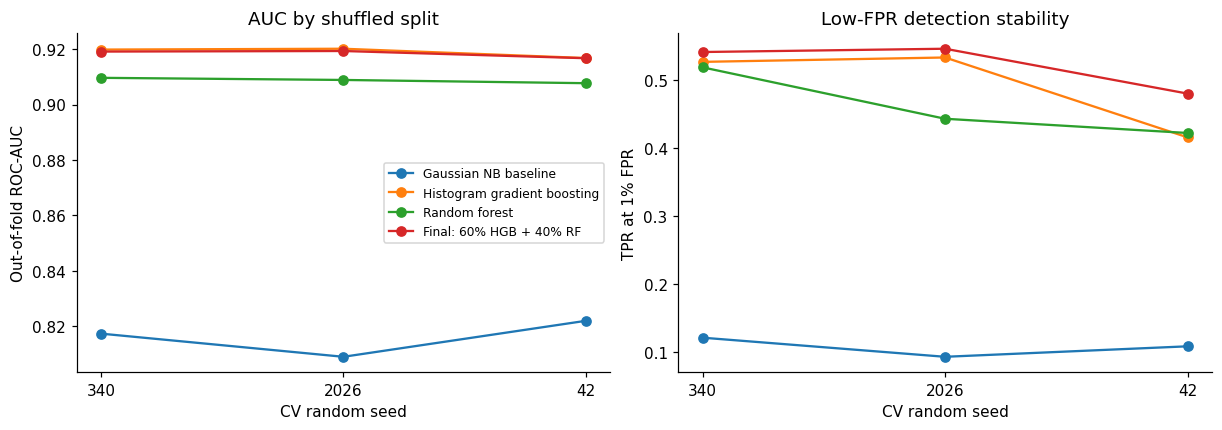

In [20]:
fig,axs=plt.subplots(1,2,figsize=(11,3.8),constrained_layout=True)
for name,g in repeat_results.groupby('Algorithm',sort=False):
    axs[0].plot(g['Seed'].astype(str),g['ROC-AUC'],marker='o',label=name)
    axs[1].plot(g['Seed'].astype(str),g['TPR@1%FPR'],marker='o',label=name)
axs[0].set(xlabel='CV random seed',ylabel='Out-of-fold ROC-AUC',title='AUC by shuffled split')
axs[1].set(xlabel='CV random seed',ylabel='TPR at 1% FPR',title='Low-FPR detection stability')
axs[0].legend(fontsize=8)
plt.show()

## 8. Deployment-style validation: a threshold without leakage

AUC/TPR@1% are **ranking** metrics: `predictTest` only needs to return scores. In a deployed filter, however, one must choose an actual **spam threshold**. The threshold must be calibrated on *previously labeled calibration emails*, **not** on the final evaluation set.

Demonstration below (completely separate from the five-fold results):

- 60% training emails: fit the final model;
- 20% calibration emails: select a threshold intended to flag no more than 1% of ham;
- 20% untouched evaluation emails: report what that calibrated threshold actually achieves.

With only ~175 ham examples in calibration, approximately **one** false positive corresponds to 1%. This estimate is noisy, and real-world performance may differ. Keeping suspicious messages in a recoverable quarantine folder is safer than deleting them automatically.

In [21]:
all_indices=np.arange(len(y))
idx_train_cal,idx_evaluation=train_test_split(all_indices,test_size=.2,stratify=y,random_state=SEED)
idx_train,idx_cal=train_test_split(idx_train_cal,test_size=.25,stratify=y[idx_train_cal],random_state=SEED)
print('Training:',len(idx_train), 'Calibration:',len(idx_cal), 'Untouched evaluation:',len(idx_evaluation))

calibrated_model=make_final_ensemble().fit(X[idx_train],y[idx_train])
cal_scores=scores_for_spam(calibrated_model,X[idx_cal])
eval_scores=scores_for_spam(calibrated_model,X[idx_evaluation])

# Select a conservative cutoff using only labeled calibration ham.
def conservative_threshold_at_fpr(neg_scores, target=0.01):
    neg_scores=np.sort(np.asarray(neg_scores,float))[::-1]
    permitted_fp=int(np.floor(target*len(neg_scores)))
    # Above the next highest ham score (or above maximum if zero FP allowed).
    return np.nextafter(float(neg_scores[permitted_fp]), np.inf)

threshold=conservative_threshold_at_fpr(cal_scores[y[idx_cal]==0],FPR_TARGET)
cal_pred=(cal_scores >= threshold).astype(int)
eval_pred=(eval_scores >= threshold).astype(int)

def threshold_statistics(y_true,pred):
    tn,fp,fn,tp=confusion_matrix(y_true,pred,labels=[0,1]).ravel()
    return {'TP':int(tp),'FP':int(fp),'TN':int(tn),'FN':int(fn),
            'TPR / recall':tp/(tp+fn) if tp+fn else np.nan,
            'FPR':fp/(fp+tn) if fp+tn else np.nan,
            'Precision':tp/(tp+fp) if tp+fp else np.nan}

print('Threshold calibrated without evaluation labels:',f'{threshold:.6f}')
display(pd.DataFrame([
    {'Split':'Calibration',**threshold_statistics(y[idx_cal],cal_pred)},
    {'Split':'Untouched evaluation',**threshold_statistics(y[idx_evaluation],eval_pred)},
]).round(4))
print('Evaluation ranking metrics (uses evaluation labels only for reporting):')
print({key:round(val,4) for key,val in ranking_metrics(y[idx_evaluation],eval_scores).items()})

Training: 900 Calibration: 300 Untouched evaluation: 300


Threshold calibrated without evaluation labels: 0.896367


,Split,TP,FP,TN,FN,TPR / recall,FPR,Precision
0,Calibration,37,1,175,87,0.2984,0.0057,0.9737
1,Untouched evaluation,41,0,176,83,0.3306,0.0000,1.0000


Evaluation ranking metrics (uses evaluation labels only for reporting):
{'ROC-AUC': 0.9095, 'TPR@1%FPR': 0.621, 'Average precision': 0.9119}


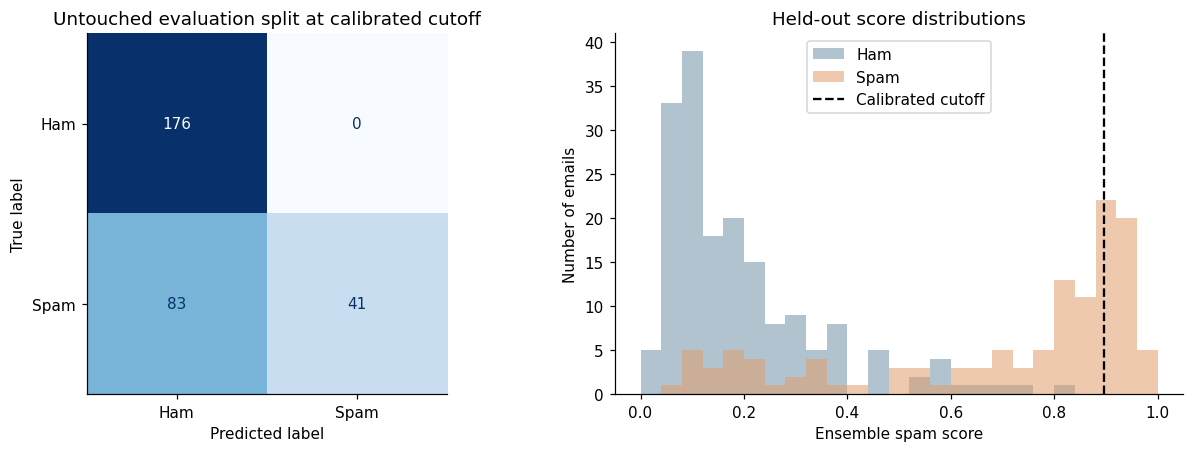

In [22]:
fig,axs=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
ConfusionMatrixDisplay.from_predictions(y[idx_evaluation],eval_pred,
    display_labels=['Ham','Spam'],cmap='Blues',colorbar=False,ax=axs[0])
axs[0].set_title('Untouched evaluation split at calibrated cutoff')
for label,name,color in [(0,'Ham','#7292A8'),(1,'Spam','#E29D6A')]:
    axs[1].hist(eval_scores[y[idx_evaluation]==label],bins=np.linspace(0,1,26),
                alpha=.55,label=name,color=color)
axs[1].axvline(threshold,color='black',ls='--',label='Calibrated cutoff')
axs[1].set(xlabel='Ensemble spam score',ylabel='Number of emails',title='Held-out score distributions')
axs[1].legend()
plt.show()

### 8.1 Inspect the errors

There are no raw message bodies in this dataset. We can still inspect which rows are false positives/negatives and compare their feature values. **Do not** draw conclusions about specific words or senders: the 30 feature names were not provided, so the columns only have numeric identifiers.

In [23]:
errors=pd.DataFrame({
    'Original row':idx_evaluation,
    'True label':y[idx_evaluation],
    'Spam score':eval_scores,
    'Predicted label':eval_pred,
    'Missing feature count':missing_mask[idx_evaluation].sum(axis=1),
})
errors['Error type']=np.select([
    (errors['True label']==0)&(errors['Predicted label']==1),
    (errors['True label']==1)&(errors['Predicted label']==0)],
    ['False positive (ham flagged)','False negative (spam missed)'],
    default='Correct')
error_rows=errors[errors['Error type']!='Correct']
print('Number of threshold errors:',len(error_rows))
display(error_rows.sort_values('Spam score',ascending=False).head(15).round(4))

Number of threshold errors: 83


,Original row,True label,Spam score,Predicted label,Missing feature count,Error type
91,203,1,0.8951,0,3,False negative (spam missed)
0,1011,1,0.8943,0,3,False negative (spam missed)
221,1090,1,0.8942,0,9,False negative (spam missed)
7,300,1,0.8936,0,5,False negative (spam missed)
175,1370,1,0.8847,0,4,False negative (spam missed)
95,723,1,0.8832,0,11,False negative (spam missed)
269,1123,1,0.8794,0,7,False negative (spam missed)
151,151,1,0.8758,0,11,False negative (spam missed)
121,650,1,0.8692,0,8,False negative (spam missed)
42,51,1,0.8650,0,4,False negative (spam missed)


### 8.2 Permutation importance on untouched evaluation data

Randomly shuffle a feature across held-out emails and observe how much ROC-AUC declines. This reveals features whose values/missingness affect the fitted ensemble. The measurement can be unstable with correlated features; it describes predictive importance, **not causation**.

,Feature,Mean AUC decrease,Std across shuffles
19,Feature 20,0.0686,0.0050
8,Feature 09,0.0306,0.0053
4,Feature 05,0.0187,0.0040
6,Feature 07,0.0126,0.0023
29,Feature 30,0.0102,0.0069
3,Feature 04,0.0096,0.0086
10,Feature 11,0.0092,0.0033
28,Feature 29,0.0074,0.0028
0,Feature 01,0.0073,0.0006
26,Feature 27,0.0045,0.0044


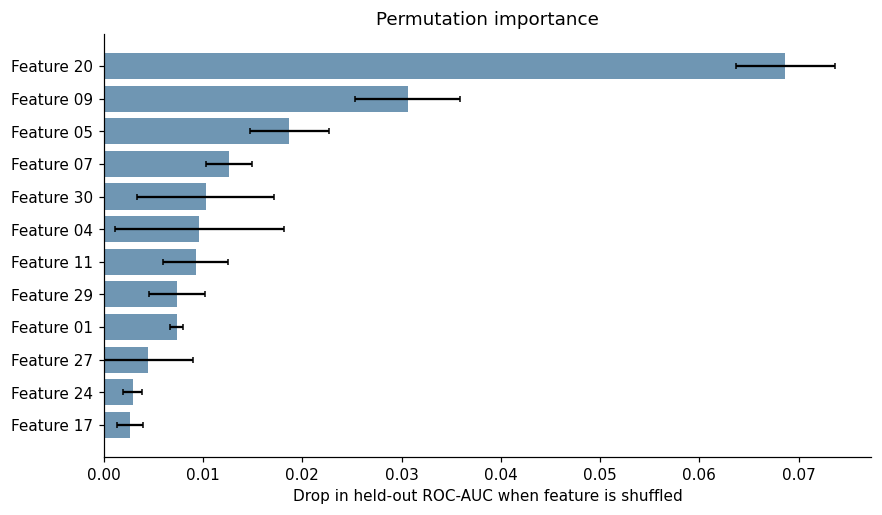

In [24]:
perm=permutation_importance(
    calibrated_model, X[idx_evaluation], y[idx_evaluation],
    scoring='roc_auc',n_repeats=3,random_state=SEED,n_jobs=1
)
importance=(pd.DataFrame({'Feature':feature_names,
                          'Mean AUC decrease':perm.importances_mean,
                          'Std across shuffles':perm.importances_std})
            .sort_values('Mean AUC decrease',ascending=False))
display(importance.head(12).round(4))
imp_top=importance.head(12).iloc[::-1]
fig,ax=plt.subplots(figsize=(9,5))
ax.barh(imp_top['Feature'],imp_top['Mean AUC decrease'],xerr=imp_top['Std across shuffles'],
        color='#6F96B3',capsize=2)
ax.axvline(0,lw=1,color='gray')
ax.set(xlabel='Drop in held-out ROC-AUC when feature is shuffled',title='Permutation importance')
plt.show()

## 9. Final `predictTest` implementation and grading compatibility

The instructor **requires the exact header** `def predictTest(trainFeatures,trainLabels,testFeatures):`. A new model is fitted **only from `trainFeatures` and `trainLabels`**; `testFeatures` is used strictly to produce test scores. Do not train on `spamTrain2.csv` unless and until its labels have officially been released for training. Do not submit this entire notebook in place of `classifySpam.py`; the Canvas submission wants the standalone Python file.

The implementation below mirrors the separately provided final `classifySpam.py` (60% native-missingness gradient boosting + 40% median-imputed random forest). The helper is repeated here to make the notebook self-contained.

In [25]:
def predictTest(trainFeatures,trainLabels,testFeatures):
    trainFeatures=np.asarray(trainFeatures,dtype=float)
    trainLabels=np.asarray(trainLabels).ravel()
    testFeatures=np.asarray(testFeatures,dtype=float)

    train_nan=np.where(trainFeatures==-1,np.nan,trainFeatures)
    test_nan=np.where(testFeatures==-1,np.nan,testFeatures)

    boosted=HistGradientBoostingClassifier(
        max_iter=350,learning_rate=.05,max_leaf_nodes=4,
        min_samples_leaf=20,l2_regularization=1.0,random_state=340
    )
    boosted.fit(train_nan,trainLabels)
    boosted_scores=boosted.predict_proba(test_nan)[:,1]

    forest=make_pipeline(
        SimpleImputer(missing_values=-1,strategy='median',add_indicator=True),
        RandomForestClassifier(n_estimators=300,min_samples_leaf=3,
            max_features='sqrt',n_jobs=1,random_state=340)
    )
    forest.fit(trainFeatures,trainLabels)
    forest_scores=forest.predict_proba(testFeatures)[:,1]
    return .60*boosted_scores+.40*forest_scores

# Mimic what the grader will do: pass ONLY training arrays and held-out features.
train_idx,val_idx=train_test_split(np.arange(len(y)),test_size=.20,stratify=y,random_state=987)
test_scores=predictTest(X[train_idx],y[train_idx],X[val_idx])
assert test_scores.shape==(len(val_idx),)
assert np.all(np.isfinite(test_scores)) and np.all((0<=test_scores)&(test_scores<=1))
print('Classifier interface: PASS')
print('Held-out check:',{k:round(v,4) for k,v in ranking_metrics(y[val_idx],test_scores).items()})

Classifier interface: PASS
Held-out check: {'ROC-AUC': 0.8943, 'TPR@1%FPR': 0.5484, 'Average precision': 0.8978}


In [26]:
# Extra safety check: the notebook's VotingClassifier ensemble and the final
# predictTest implementation should agree on the same training/validation split.
reference=make_final_ensemble().fit(X[train_idx],y[train_idx])
reference_scores=reference.predict_proba(X[val_idx])[:,1]
max_difference=np.max(np.abs(reference_scores-test_scores))
print(f'Max difference between equivalent implementations: {max_difference:.3e}')
assert np.allclose(reference_scores,test_scores,atol=1e-10), 'Models differ unexpectedly.'
print('Final implementation reproduces comparison ensemble: PASS')

Max difference between equivalent implementations: 0.000e+00
Final implementation reproduces comparison ensemble: PASS


## 10. Findings and report-ready interpretation

After running the notebook, use the **actual printed metrics** and plots above in your write-up. The initial labeled set has 1,500 emails and 30 anonymized word-proportion predictors, many zeros, and about one-fifth missing entries. Missingness is encoded by `-1` and must be handled consistently.

1. **Why tree-based learning?** Random forests and gradient-boosted trees model nonlinear interactions and do not need scaling. The boosted model can learn how to route missing observations.
2. **Why compare Gaussian NB and linear models?** Gaussian NB is the course's required baseline; logistic regression and RBF SVM reveal how far a simple linear ranking and a nonlinear kernel can go.
3. **Why a blend?** The ensemble can improve performance in the critical 1% FPR region even when boosting alone is competitive on full AUC. Favor *validated* low-FPR behavior over tiny changes in average AUC.
4. **What are the limits?** Only 1,500 labeled messages and ~879 ham emails are available. Estimating the 1% operating point from so few negatives is unstable, particularly in a single fold. Model selection on these same emails may inflate the estimates.
5. **How to deploy?** Return continuous scores, calibrate a decision threshold on **separate, recent labeled mail**, quarantine rather than permanently delete uncertain emails, solicit user corrections, and monitor both false-positive rates and missed spam as behavior drifts.

**Assignment delivery checklist:** The Canvas submission should contain `classifySpam.py` and one PDF/Word report (≤5 pages, ≥12-point body font, ≥1-inch margins). This notebook is an optional, fully reproducible exploration artifact; it does **not** replace either required file. If a second labeled batch is made available after the pre-submission, re-run the EDA/experiments on the expanded labeled training set and re-fit the model.